# Species Distribution Modelling (SDM): Prepare the Datasets

*Section 11 — Case study: species distribution modelling, notebook 1 of 2.* Previous: `10_case_study_icesat2_bathymetry/05_cshelph_bathymetry`. Next: `02_species_distribution_modelling`.

Species distribution modelling is also called habitat suitability modelling. In this case study you will model the distribution of the Snowdon beetle (*Chrysolina cerealis*) in Snowdonia, Wales. This first notebook prepares the input datasets for the model in the second notebook.

**You will learn:**
- how to convert a CSV of species sightings (lat/lon) into a projected vector layer with GeoPandas;
- how to rasterise a study area and a habitat map (`rsgispy.imageutils.rasterise.rasterise_vec_lyr`);
- how to create a distance-to-habitat image for each habitat class (`rsgispy.imagecalc.distance.calc_dist_to_img_vals`);
- how to map the results (`rsgispy.mapping.raster`).

**Before you start:** sections 1-3 (`01_getting_started`, `02_making_maps`, `03_vector_data_and_zonal_stats`).

**Data:** `../data/sdm/sightings/Chrysolina_cerealis.csv`, `../data/sdm/environmental_data/` (`Study_Area.geojson`, `Phase1_Veg.geojson`, `Elevation.tif`) and `../data/sdm/Phase1-Habitat-DominantSpecies-codes-2008.xlsx`. The outputs are written to `outputs/` and used by the next notebook.

**Run time:** about 1 minute.

## 1. Create Vector Sighting Data

 * Import the pandas and geopandas modules needed for this first step.
 * Define the file path to the sighting CSV file
 * Read the CSV file using pandas into a Dataframe
 * Convert Dataframe to a geopandas GeoDataframe - using Lat / Lon (WGS84)
 * Reproject the GeoDataframe to OSGB (EPSG:27700)
 * Save as a GeoPackage file which can then be loaded within the GIS

In [1]:
import os

import geopandas
import pandas

out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

In [2]:
sighting_data_csv = "../data/sdm/sightings/Chrysolina_cerealis.csv"

In [3]:
cc_data_df = pandas.read_csv(sighting_data_csv, header=0)
cc_data_df.head()

,Scientific name,Common name,Occurrence status,Year,Latitude (WGS84),Longitude (WGS84),Coordinate uncertainty (m),Recorder,Individual count,Institution code
0,Chrysolina cerealis,Rainbow Leaf Beetle,present,1978.0,53.06999,-4.05370,1000,John Parry,13.0,NRW
1,Chrysolina cerealis,Rainbow Leaf Beetle,present,1902.0,53.06999,-4.05370,1000,J. Chappell,13.0,NRW
2,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08743,-4.08439,1000,Unknown,1.0,NRW
3,Chrysolina cerealis,Rainbow Leaf Beetle,present,2007.0,53.08164,-4.08464,1,Michael Shackshaft,1.0,NRW
4,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08158,-4.08486,100,Adrian Fowles,1.0,NRW


In [4]:
cc_geo_data_gdf = geopandas.GeoDataFrame(
    cc_data_df,
    geometry=geopandas.points_from_xy(
        cc_data_df["Longitude (WGS84)"], cc_data_df["Latitude (WGS84)"]
    ),
    crs="EPSG:4326",
)
cc_geo_data_gdf.head()

,Scientific name,Common name,Occurrence status,Year,Latitude (WGS84),Longitude (WGS84),Coordinate uncertainty (m),Recorder,Individual count,Institution code,geometry
0,Chrysolina cerealis,Rainbow Leaf Beetle,present,1978.0,53.06999,-4.05370,1000,John Parry,13.0,NRW,POINT (-4.0537 53.06999)
1,Chrysolina cerealis,Rainbow Leaf Beetle,present,1902.0,53.06999,-4.05370,1000,J. Chappell,13.0,NRW,POINT (-4.0537 53.06999)
2,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08743,-4.08439,1000,Unknown,1.0,NRW,POINT (-4.08439 53.08743)
3,Chrysolina cerealis,Rainbow Leaf Beetle,present,2007.0,53.08164,-4.08464,1,Michael Shackshaft,1.0,NRW,POINT (-4.08464 53.08164)
4,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08158,-4.08486,100,Adrian Fowles,1.0,NRW,POINT (-4.08486 53.08158)


In [5]:
cc_geo_osgb_data_gdf = cc_geo_data_gdf.to_crs(epsg=27700)
cc_geo_osgb_data_gdf.head()

,Scientific name,Common name,Occurrence status,Year,Latitude (WGS84),Longitude (WGS84),Coordinate uncertainty (m),Recorder,Individual count,Institution code,geometry
0,Chrysolina cerealis,Rainbow Leaf Beetle,present,1978.0,53.06999,-4.05370,1000,John Parry,13.0,NRW,POINT (262500.145 354498.456)
1,Chrysolina cerealis,Rainbow Leaf Beetle,present,1902.0,53.06999,-4.05370,1000,J. Chappell,13.0,NRW,POINT (262500.145 354498.456)
2,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08743,-4.08439,1000,Unknown,1.0,NRW,POINT (260500.63 356497.596)
3,Chrysolina cerealis,Rainbow Leaf Beetle,present,2007.0,53.08164,-4.08464,1,Michael Shackshaft,1.0,NRW,POINT (260465.146 355854.086)
4,Chrysolina cerealis,Rainbow Leaf Beetle,present,1989.0,53.08158,-4.08486,100,Adrian Fowles,1.0,NRW,POINT (260450.218 355847.842)


In [6]:
cc_geo_osgb_data_gdf.to_file(
    os.path.join(out_dir, "Chrysolina_cerealis_osgb.gpkg"),
    layer="Chrysolina_cerealis_osgb",
    driver="GPKG",
)

## 2. Rasterise the Study Site Layer

The elevation image is used as the reference image, defining the projection, extent and pixel size (20 m) of all the images.

In [7]:
import rsgispy
import rsgispy.imageutils.rasterise

In [8]:
# Study Site Vector
study_site_vec_file = "../data/sdm/environmental_data/Study_Area.geojson"
study_site_vec_lyr = "Study_Area"

# Elevation Image is used as the reference for
# Project and Pixel Size
elevation_img = "../data/sdm/environmental_data/Elevation.tif"

# Output Study Site Image
study_site_img = os.path.join(out_dir, "Study_Area.tif")

In [9]:
# Rasterise the Study Site Layer
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    vec_file=study_site_vec_file,
    vec_lyr=study_site_vec_lyr,
    input_img=elevation_img,
    output_img=study_site_img,
    burn_val=1,
    att_column=None,
    use_vec_extent=False,
    thematic=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=0,
)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

## 3. Rasterise Phase 1 (Vegetation Classification)

https://datamap.gov.wales/layergroups/geonode:nrw_terrestrial_phase_1_habitat_survey

The pixel values are taken from the `Class` column of the vector layer (`att_column`), rather than a single burn value.

In [10]:
phase1_vec_file = "../data/sdm/environmental_data/Phase1_Veg.geojson"
phase1_vec_lyr = "Phase1_Veg"

In [11]:
# Output Phase 1 Image
phase1_img = os.path.join(out_dir, "Phase1_Cat.tif")

In [12]:
# Rasterise the Phase 1 Vector layer where the
# pixel values will be from the "Class" column.
rsgispy.imageutils.rasterise.rasterise_vec_lyr(
    vec_file=phase1_vec_file,
    vec_lyr=phase1_vec_lyr,
    input_img=elevation_img,
    output_img=phase1_img,
    att_column="Class",
    use_vec_extent=False,
    thematic=True,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
    no_data_val=0,
)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

### 3.1 Create a Phase 1 Habitat Codes and Class Look Up Table

In [13]:
import math

In [14]:
phase1_gdf = geopandas.read_file(phase1_vec_file, layer=phase1_vec_lyr)
phase1_gdf.head()

,Label,Phase1_Cod,Class,geometry
0,"Mosaic of:50% B.1.1,50% E.2.1",mosaic,46.0,"MULTIPOLYGON (((259898.03 353244.91, 259934.94..."
1,"Mosaic of:98% B.1.1,2% E.2.1",mosaic,46.0,"MULTIPOLYGON (((260094.822 352569.765, 259949...."
2,"Mosaic of:98% B.1.1,2% C.2",mosaic,46.0,"MULTIPOLYGON (((260398.56 355776.16, 260409.41..."
3,B.1.1,B.1.1,5.0,"MULTIPOLYGON (((258046.32 352360.501, 257491.3..."
4,B.4,B.4,9.0,"MULTIPOLYGON (((257491.331 352376.345, 257444...."


In [15]:
cls_id_lut = dict()
for index, row in phase1_gdf.iterrows():
    if not math.isnan(row["Class"]):
        cls_id = int(row["Class"])
        if (cls_id > 0) and (cls_id not in cls_id_lut):
            cls_name = row["Phase1_Cod"]
            if cls_name != "NA":
                cls_id_lut[cls_id] = row["Phase1_Cod"]

In [16]:
cls_id_lut

{46: 'mosaic',
 5: 'B.1.1',
 9: 'B.4',
 6: 'B.1.2',
 25: 'E.2.1',
 17: 'D.2',
 32: 'G.2',
 39: 'I.2.2',
 10: 'B.5',
 4: 'A.2.1',
 7: 'B.2.2',
 16: 'D.1.1',
 31: 'G.1',
 43: 'J.3.6',
 1: 'A.1.1.1',
 13: 'C.1.1',
 38: 'I.2.1',
 44: 'J.3.7',
 12: 'B.5.2',
 35: 'I.1.2.1',
 19: 'D.5',
 34: 'I.1.2',
 24: 'E.2',
 42: 'J.1.5',
 40: 'J.1.2',
 41: 'J.1.3',
 3: 'A.1.2.2',
 21: 'E.1.6.1',
 23: 'E.1.8',
 45: 'J.4',
 37: 'I.1.4.1',
 14: 'C.2',
 15: 'C.3.2',
 36: 'I.1.4',
 26: 'E.2.3',
 11: 'B.5.1',
 29: 'E.4',
 18: 'D.3',
 28: 'E.3.2',
 22: 'E.1.7',
 20: 'D.6',
 27: 'E.3',
 30: 'F.1',
 2: 'A.1.1.2',
 8: 'B.3.1',
 33: 'I.1'}

In [17]:
phase1_codes_df = pandas.read_excel(
    "../data/sdm/Phase1-Habitat-DominantSpecies-codes-2008.xlsx",
    sheet_name="Habitat list",
)
phase1_codes_df.head()

,JNCC Phase 1 habitat survey handbook code,1st level category,2nd level category,3rd level category,4th level category,JNCC Phase 1 habitat survey handbook name,Phase 1 habitat survey of Wales code,Phase 1 habitat survey of Wales name
0,A,A,NaN,NaN,NaN,Woodland and scrub,NaN,NaN
1,A1,NaN,A1,NaN,NaN,Woodland,NaN,NaN
2,A1.1,NaN,NaN,A1.1,NaN,Broadleaved woodland - semi-natural,NaN,NaN
3,A1.1.1,NaN,NaN,NaN,A1.1.1,Broadleaved woodland - semi-natural,A.1.1.1,Semi-natural broadleaved woodland
4,A1.1.2,NaN,NaN,NaN,A1.1.2,Broadleaved woodland - plantation,A.1.1.2,Planted broadleaved woodland


In [18]:
cls_names_lut = dict()
for index, row in phase1_codes_df.iterrows():
    cls_name = f"{row['Phase 1 habitat survey of Wales code']}"
    if (cls_name != "" and cls_name != "?" and cls_name.lower() != "nan") and (
        cls_name not in cls_names_lut
    ):
        cls_hab_name = f"{row['Phase 1 habitat survey of Wales name']}"
        if cls_hab_name != "" and cls_hab_name.lower() != "nan":
            cls_names_lut[cls_name] = cls_hab_name

In [19]:
cls_names_lut

{'A.1.1.1': 'Semi-natural broadleaved woodland',
 'A.1.1.2': 'Planted broadleaved woodland',
 'A.1.2.1': 'Semi-natural coniferous woodland',
 'A.1.2.2': 'Planted coniferous woodland',
 'A.1.3.1': 'Semi-natural mixed woodland',
 'A.1.3.2': 'Planted mixed woodland',
 'A.2.1': 'Dense scrub',
 'A.2.2': 'Scattered scrub',
 'A.3.1': 'Scattered broadleaved trees',
 'A.3.2': 'Scattered coniferous trees',
 'A.3.3': 'Scattered mixed trees',
 'A.4.1': 'Felled broadleaved woodland',
 'A.4.2': 'Felled coniferous woodland',
 'A.4.3': 'Felled mixed woodland',
 'B.1.1': 'Unimproved acid grassland',
 'B.1.2': 'Semi-improved acid grassland',
 'B.2.1': 'Unimproved neutral grassland',
 'B.2.2': 'Semi-improved neutral grassland',
 'B.3.1': 'Unimproved calcareous grassland',
 'B.3.2': 'Semi-improved calcareous grassland',
 'B.4': 'Improved grassland',
 'B.5': 'Marshy grassland',
 'B.5.1': 'Marshy grassland Juncus dominated',
 'B.5.2': 'Marshy grassland Molinia dominated',
 'C.1.1': 'Bracken',
 'C.1.2': 'Sca

Using these two look up tables we should be able to find the names of the classes associated with the pixel values within the region of Phase 1 which we have rasterised.

Let's try an example:

In [20]:
pixel_val = 9
print(cls_names_lut[cls_id_lut[pixel_val]])

Improved grassland


In [21]:
pixel_val = 13
print(cls_names_lut[cls_id_lut[pixel_val]])

Bracken


### 3.2 Add Class Names and a Colour Table to the Phase 1 Image

The Phase 1 image is a thematic (categorical) image. To display it with sensible colours (and a legend) we give each class its habitat name (from the two look up tables above) and a colour (a random colour for each class here) with `set_thematic_classes`, which also marks the image as thematic and calculates the thematic image statistics.

> **RSGISLib users:** rsgispy does not use raster attribute tables (RATs); `set_thematic_classes` stores the class names and colours in the image (read them back with `get_thematic_classes`), replacing `rastergis.set_class_names` and the colour table columns of the RAT.

In [22]:
import numpy
import rsgispy.imageutils.colourtable
import rsgispy.imageutils.stats

rng = numpy.random.default_rng(42)
phase1_classes = dict()
for cls_id in sorted(cls_id_lut):
    phase1_code = cls_id_lut[cls_id]
    # Use the habitat name where there is one, otherwise the Phase 1 code.
    cls_name = cls_names_lut.get(phase1_code, phase1_code)
    cls_clr = [int(v) for v in rng.integers(20, 255, 3)]
    phase1_classes[cls_id] = (cls_name, cls_clr)
rsgispy.imageutils.colourtable.set_thematic_classes(phase1_img, phase1_classes)
print(f"{len(phase1_classes)} classes, e.g. 9: {phase1_classes[9][0]}")

46 classes, e.g. 9: Improved grassland


## 4. Create Phase 1 Habitat Distance Images

Land cover and habitat maps are typically not ideal for species distribution modelling as the sighting could be within a neighbouring pixel to land cover which that species is associated with but the model would not know that.

Therefore, it is useful to calculate the distance to each of the land covers and we will enter the distance images into the model rather than the categorical data.

`calc_dist_to_img_vals` calculates, for every pixel, the distance (in map units, i.e. metres, as `unit_geo=True`) to the nearest pixel with one of the values in `pxl_vals`. GeoTIFF outputs are compressed by default in rsgispy, so no environment set-up is needed.

In [23]:
import rsgispy.imagecalc.distance
import rsgispy.tools.strings

In [24]:
phase1_dist_dir = os.path.join(out_dir, "phase1_dist_imgs")
os.makedirs(phase1_dist_dir, exist_ok=True)

In [25]:
for cls_pxl_id in cls_id_lut:
    phase1_code = cls_id_lut[cls_pxl_id]
    calc_dist = False
    if phase1_code in cls_names_lut:
        print(cls_names_lut[phase1_code])
        phase1_cls_name_str = rsgispy.tools.strings.check_str(
            cls_names_lut[phase1_code],
            rm_non_ascii=True,
            rm_dashs=True,
            rm_spaces=True,
            rm_punc=True,
        )
        print(f"\t{phase1_cls_name_str}")
        dist_img = os.path.join(phase1_dist_dir, f"{phase1_cls_name_str}_dist.tif")
        calc_dist = True
    elif phase1_code == "mosaic":
        dist_img = os.path.join(phase1_dist_dir, "mosaic_dist.tif")
        calc_dist = True
    if calc_dist:
        rsgispy.imagecalc.distance.calc_dist_to_img_vals(
            phase1_img,
            dist_img,
            pxl_vals=[cls_pxl_id],
            img_band=1,
            max_dist=None,
            unit_geo=True,
            gdalformat="GTIFF",
            no_data_val=None,
            out_no_data_val=-9999,
            use_pbar=False,
        )
        rsgispy.imageutils.stats.pop_img_stats(
            dist_img, no_data_val=-9999, calc_pyramids=True, use_pbar=False
        )

Unimproved acid grassland
	Unimproved_acid_grassland


Improved grassland
	Improved_grassland


Semi-improved acid grassland
	Semi_improved_acid_grassland
Acid/neutral flush
	Acidneutral_flush


Wet heath
	Wet_heath


Running water


	Running_water
Spoil
	Spoil


... (7 outputs left out)

Acid/neutral rock
	Acidneutral_rock
Upland species rich ledges
	Upland_species_rich_ledges
Non-ruderal herb and fern
	Non_ruderal_herb_and_fern
Other rock exposure
	Other_rock_exposure


Brophyte-dominated spring
	Brophyte_dominated_spring
Marshy grassland Juncus dominated
	Marshy_grassland_Juncus_dominated
Bare peat
	Bare_peat
Lichen/bryophyte heath
	Lichenbryophyte_heath


Basin mire
	Basin_mire
Wet modified bog
	Wet_modified_bog
Basic dry heath/calcareous grassland mosaic
	Basic_dry_heathcalcareous_grassland_mosaic
Fen
	Fen


Swamp
	Swamp
Planted broadleaved woodland
	Planted_broadleaved_woodland
Unimproved calcareous grassland
	Unimproved_calcareous_grassland
Natural rock exposure
	Natural_rock_exposure


## 5. Make Some Maps

You will probably want to open the data within QGIS or similar to visualise the data but within the notebook we'll create some maps to see what the data looks like.

In [26]:
import matplotlib.pyplot as plt
import rsgispy.mapping.raster

%matplotlib inline

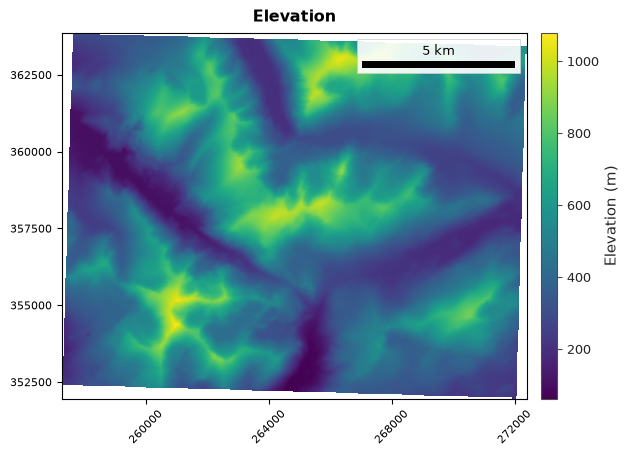

In [27]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(6, 5))

im = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax,
    input_img=elevation_img,
    img_band=1,
    title_str="Elevation",
    show_colour_bar=True,
    cbar_label="Elevation (m)",
)
ax.tick_params(axis="x", labelrotation=45)

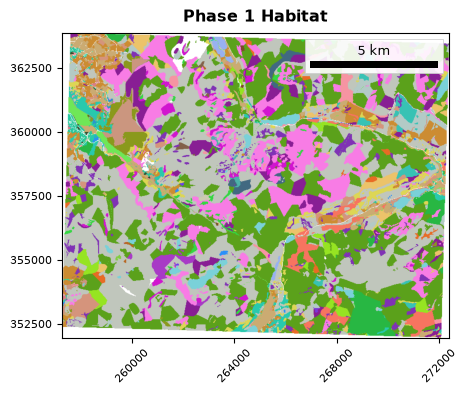

In [28]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

im = rsgispy.mapping.raster.create_thematic_raster_map(
    ax,
    input_img=phase1_img,
    title_str="Phase 1 Habitat",
)
ax.tick_params(axis="x", labelrotation=45)

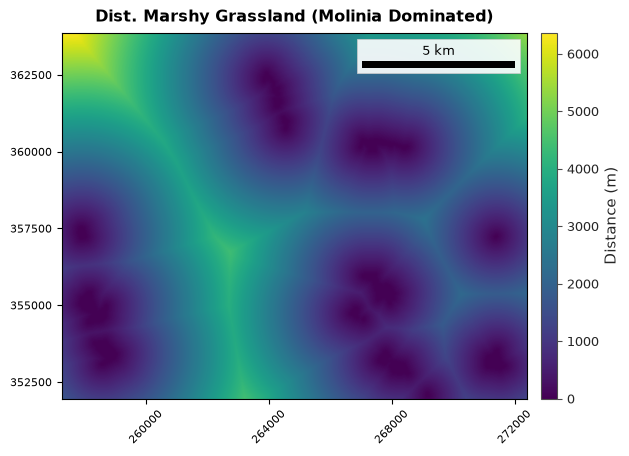

In [29]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(6, 5))

im = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax,
    input_img=os.path.join(phase1_dist_dir, "Marshy_grassland_Molinia_dominated_dist.tif"),
    img_band=1,
    title_str="Dist. Marshy Grassland (Molinia Dominated)",
    show_colour_bar=True,
    cbar_label="Distance (m)",
)
ax.tick_params(axis="x", labelrotation=45)